In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

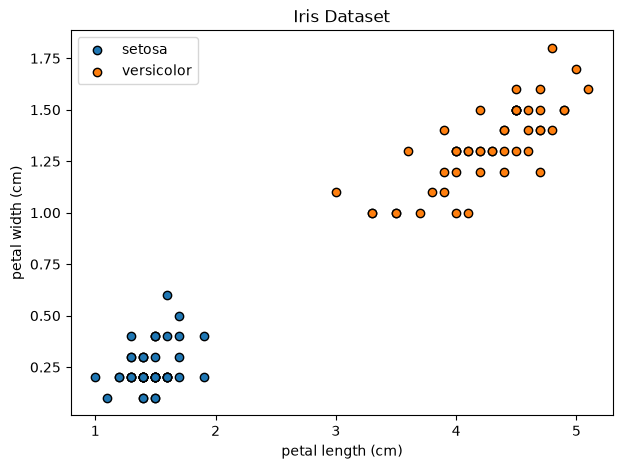

In [2]:
iris = load_iris()
X = iris.data[iris.target < 2][:, [2, 3]]
y = iris.target[iris.target < 2]
feature_names = iris.feature_names[2:4]
class_names = iris.target_names[:2]

# X = iris.data[:, [2, 3]]
# y = iris.target
# feature_names = iris.feature_names[2:4]
# class_names = iris.target_names

plt.figure(figsize=(7, 5))
for label, name in enumerate(class_names):
    plt.scatter(X[y == label, 0], X[y == label, 1], label=name, edgecolors="k")
plt.xlabel(feature_names[0])
plt.ylabel(feature_names[1])
plt.title("Iris Dataset")
plt.legend()
plt.show()

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

linear_svm = SVC(kernel="linear")
linear_svm.fit(X_train, y_train)

y_pred = linear_svm.predict(X_test)
linear_test_accuracy = accuracy_score(y_test, y_pred)

print("Test accuracy:", linear_test_accuracy)

Test accuracy: 1.0


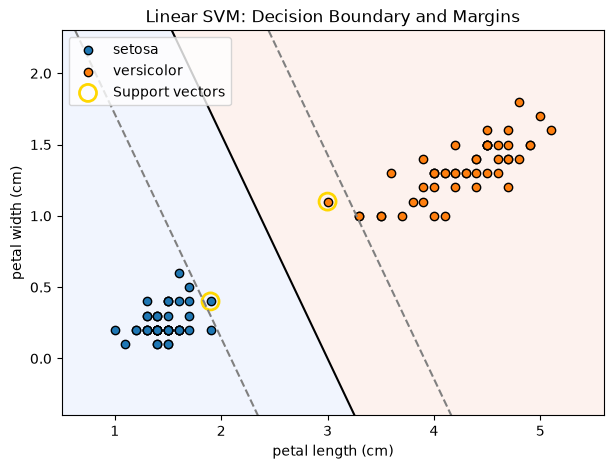

Number of support vectors: 2


In [4]:
def plot_svm_boundary(model, X, y, title):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 400),
        np.linspace(y_min, y_max, 400)
    )
    scores = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    plt.figure(figsize=(7, 5))
    plt.contourf(xx, yy, scores, levels=[-100, 0, 100], alpha=0.12, cmap="coolwarm")
    plt.contour(xx, yy, scores, levels=[-1, 0, 1], colors=["gray", "black", "gray"],
                linestyles=["--", "-", "--"])
    for label, name in enumerate(class_names):
        plt.scatter(X[y == label, 0], X[y == label, 1], label=name, edgecolors="k")
    plt.scatter(
        model.support_vectors_[:, 0],
        model.support_vectors_[:, 1],
        s=150,
        facecolors="none",
        edgecolors="gold",
        linewidths=2,
        label="Support vectors"
    )
    plt.xlabel(feature_names[0])
    plt.ylabel(feature_names[1])
    plt.title(title)
    plt.legend()
    plt.show()

plot_svm_boundary(linear_svm, X, y, "Linear SVM: Decision Boundary and Margins")
print("Number of support vectors:", len(linear_svm.support_vectors_))

,Model score,Hinge loss
0,-1.0,2.0
1,0.0,1.0
2,0.5,0.5
3,1.0,0.0
4,2.0,0.0


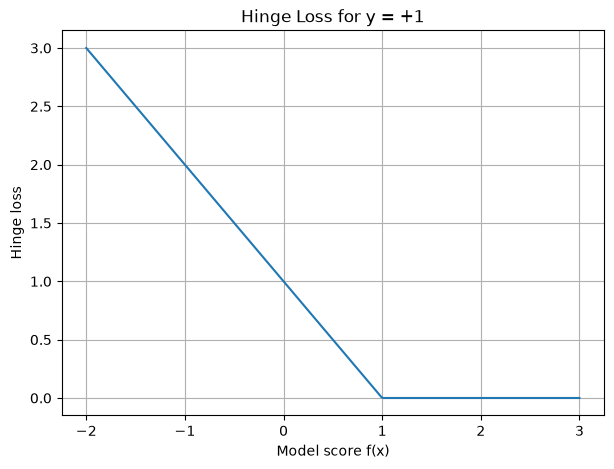

In [5]:
scores_to_check = np.array([-1, 0, 0.5, 1, 2])
true_label = 1
hinge_losses = np.maximum(0, 1 - true_label * scores_to_check)

hinge_results = pd.DataFrame({
    "Model score": scores_to_check,
    "Hinge loss": hinge_losses
})
display(hinge_results)

score_values = np.linspace(-2, 3, 300)
loss_values = np.maximum(0, 1 - score_values)

plt.figure(figsize=(7, 5))
plt.plot(score_values, loss_values)
plt.xlabel("Model score f(x)")
plt.ylabel("Hinge loss")
plt.title("Hinge Loss for y = +1")
plt.grid(True)
plt.show()

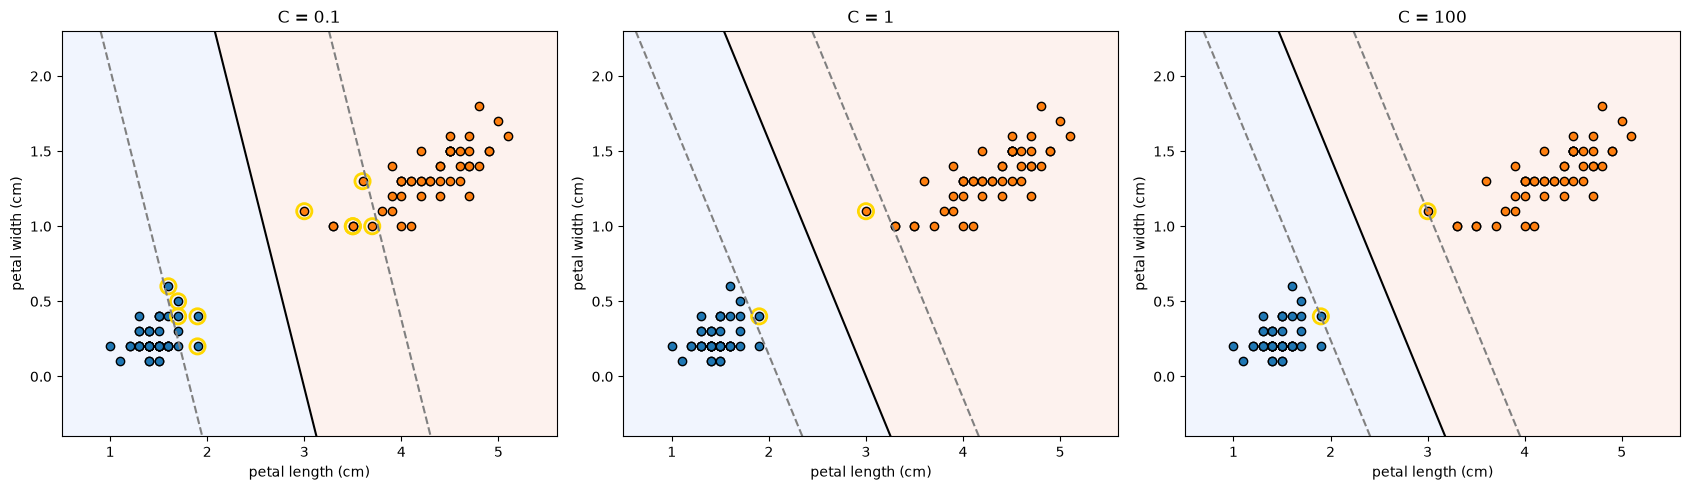

,C,Number of support vectors,Training accuracy,Testing accuracy
0,0.1,10,1.0,1.0
1,1.0,2,1.0,1.0
2,100.0,2,1.0,1.0


In [6]:
C_values = [0.1, 1, 100]
C_models = {}

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, C_value in zip(axes, C_values):
    model = SVC(kernel="linear", C=C_value)
    model.fit(X_train, y_train)
    C_models[C_value] = model

    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )
    scores = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    ax.contourf(xx, yy, scores, levels=[-100, 0, 100], alpha=0.12, cmap="coolwarm")
    ax.contour(xx, yy, scores, levels=[-1, 0, 1],
               colors=["gray", "black", "gray"], linestyles=["--", "-", "--"])
    for label, name in enumerate(class_names):
        ax.scatter(X[y == label, 0], X[y == label, 1], label=name, edgecolors="k")
    ax.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1],
               s=120, facecolors="none", edgecolors="gold", linewidths=2)
    ax.set_title(f"C = {C_value}")
    ax.set_xlabel(feature_names[0])
    ax.set_ylabel(feature_names[1])

plt.tight_layout()
plt.show()

C_summary = pd.DataFrame([
    {
        "C": C_value,
        "Number of support vectors": len(model.support_vectors_),
        "Training accuracy": accuracy_score(y_train, model.predict(X_train)),
        "Testing accuracy": accuracy_score(y_test, model.predict(X_test))
    }
    for C_value, model in C_models.items()
])
display(C_summary)

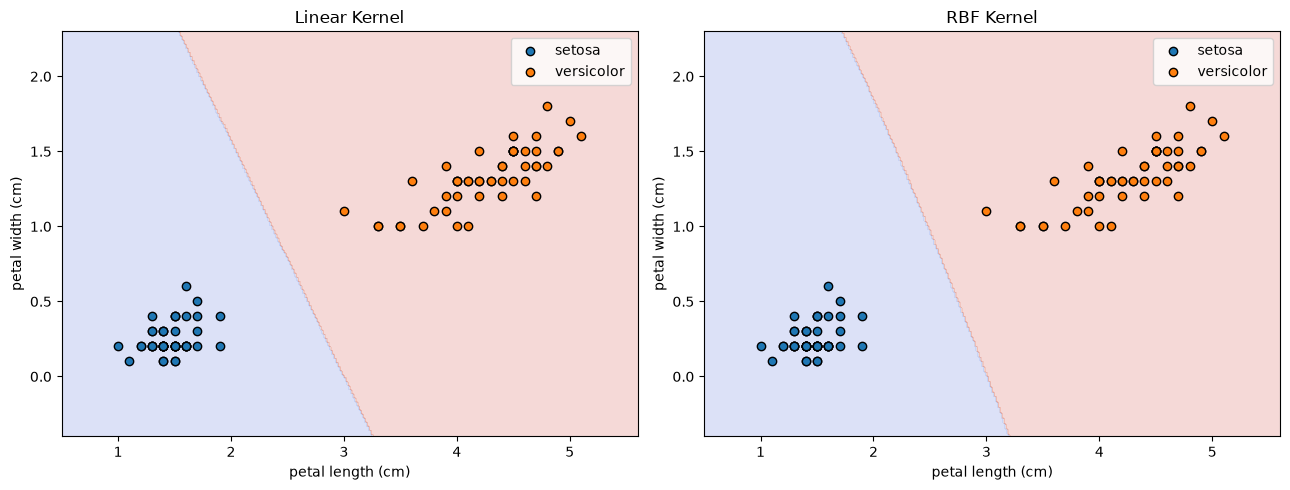

,Kernel,C,Training accuracy,Testing accuracy
0,Linear,1.0,1.0,1.0
1,RBF,1.0,1.0,1.0


In [7]:
kernel_models = {
    "Linear": SVC(kernel="linear"),
    "RBF": SVC(kernel="rbf")
}

kernel_results = []
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (kernel_name, model) in zip(axes, kernel_models.items()):
    model.fit(X_train, y_train)
    train_accuracy = accuracy_score(y_train, model.predict(X_train))
    test_accuracy = accuracy_score(y_test, model.predict(X_test))

    kernel_results.append({
        "Kernel": kernel_name,
        "C": model.C,
        "Training accuracy": train_accuracy,
        "Testing accuracy": test_accuracy
    })

    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )
    predictions = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    ax.contourf(xx, yy, predictions, alpha=0.2, cmap="coolwarm")
    for label, name in enumerate(class_names):
        ax.scatter(X[y == label, 0], X[y == label, 1], label=name, edgecolors="k")
    ax.set_title(f"{kernel_name} Kernel")
    ax.set_xlabel(feature_names[0])
    ax.set_ylabel(feature_names[1])
    ax.legend()

plt.tight_layout()
plt.show()

display(pd.DataFrame(kernel_results))

In [8]:
def average_hinge_loss(y_true, scores):
    y_true = np.asarray(y_true)
    scores = np.asarray(scores)
    losses = np.maximum(0, 1 - y_true * scores)
    return losses, losses.mean()

sample_y = [1, -1, 1]
sample_scores = [0.5, 0.2, 1.5]

sample_losses, average_loss = average_hinge_loss(sample_y, sample_scores)

for index, loss in enumerate(sample_losses, start=1):
    print(f"Sample {index} hinge loss:", loss)

print("Average hinge loss:", average_loss)

Sample 1 hinge loss: 0.5
Sample 2 hinge loss: 1.2
Sample 3 hinge loss: 0.0
Average hinge loss: 0.5666666666666667


In [9]:
model_comparison = []

for C_value, model in C_models.items():
    model_comparison.append({
        "Kernel type": "linear",
        "C value": C_value,
        "Training accuracy": accuracy_score(y_train, model.predict(X_train)),
        "Testing accuracy": accuracy_score(y_test, model.predict(X_test))
    })

for kernel_name, model in kernel_models.items():
    model_comparison.append({
        "Kernel type": kernel_name.lower(),
        "C value": model.C,
        "Training accuracy": accuracy_score(y_train, model.predict(X_train)),
        "Testing accuracy": accuracy_score(y_test, model.predict(X_test))
    })

model_comparison_df = pd.DataFrame(model_comparison)
display(model_comparison_df)

,Kernel type,C value,Training accuracy,Testing accuracy
0,linear,0.1,1.0,1.0
1,linear,1.0,1.0,1.0
2,linear,100.0,1.0,1.0
3,linear,1.0,1.0,1.0
4,rbf,1.0,1.0,1.0


In [10]:
iris_all = load_iris()
X_all = iris_all.data
y_all = iris_all.target
feature_names_all = iris_all.feature_names
class_names_all = iris_all.target_names

X_train_all, X_test_all, y_train_all, y_test_all = train_test_split(
    X_all, y_all, test_size=0.20, random_state=42, stratify=y_all
)

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import classification_report, confusion_matrix


In [11]:
all_feature_models = {
    "Linear": make_pipeline(StandardScaler(), SVC(kernel="linear", decision_function_shape="ovr")),
    "RBF": make_pipeline(StandardScaler(), SVC(kernel="rbf", decision_function_shape="ovr"))
}

all_feature_results = []

for model_name, model in all_feature_models.items():
    model.fit(X_train_all, y_train_all)
    all_feature_results.append({
        "Model": model_name,
        "Features used": X_all.shape[1],
        "Classes": len(np.unique(y_all)),
        "Training accuracy": accuracy_score(y_train_all, model.predict(X_train_all)),
        "Testing accuracy": accuracy_score(y_test_all, model.predict(X_test_all))
    })

display(pd.DataFrame(all_feature_results))


,Model,Features used,Classes,Training accuracy,Testing accuracy
0,Linear,4,3,0.975,1.000000
1,RBF,4,3,0.975,0.966667


In [12]:
for model_name, model in all_feature_models.items():
    print(model_name)
    print(classification_report(y_test_all, model.predict(X_test_all), target_names=class_names_all))
    display(pd.DataFrame(
        confusion_matrix(y_test_all, model.predict(X_test_all)),
        index=[f"Actual {name}" for name in class_names_all],
        columns=[f"Predicted {name}" for name in class_names_all]
    ))


Linear
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



,Predicted setosa,Predicted versicolor,Predicted virginica
Actual setosa,10,0,0
Actual versicolor,0,10,0
Actual virginica,0,0,10


RBF
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



,Predicted setosa,Predicted versicolor,Predicted virginica
Actual setosa,10,0,0
Actual versicolor,0,9,1
Actual virginica,0,0,10


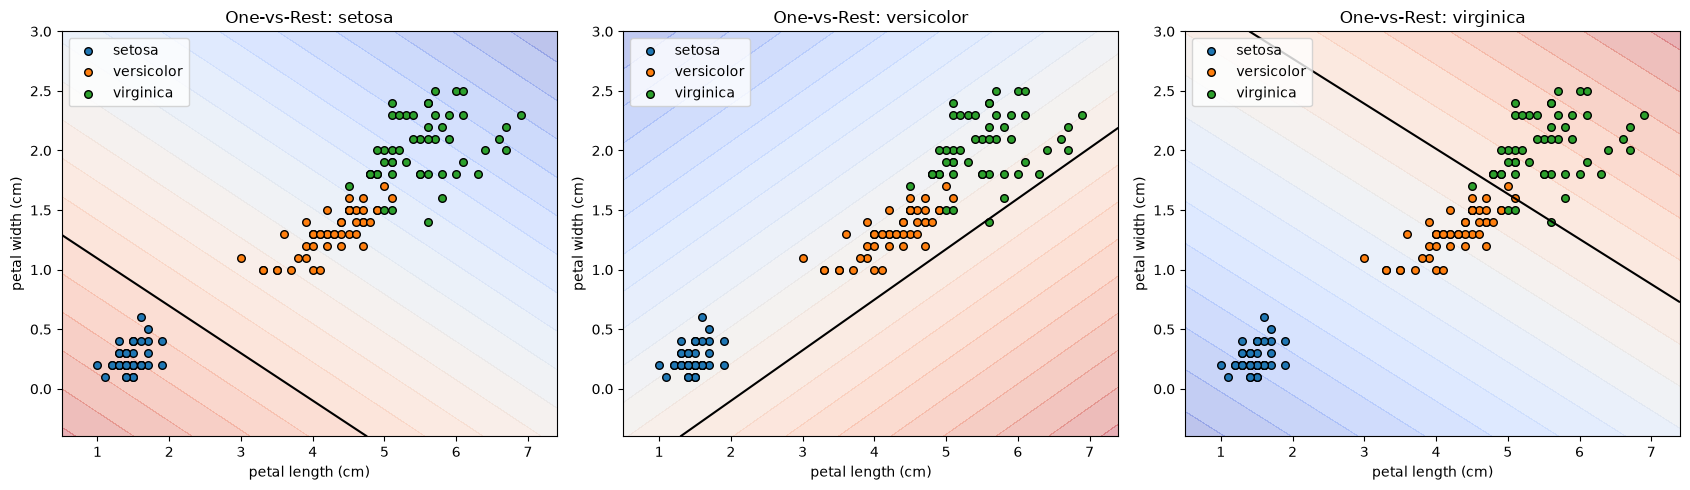

In [13]:
ovr_model = make_pipeline(
    StandardScaler(),
    OneVsRestClassifier(SVC(kernel="linear", C=1))
)
ovr_model.fit(X_train_all, y_train_all)

plot_features = [2, 3]
fixed_values = np.median(X_all, axis=0)
x_min, x_max = X_all[:, plot_features[0]].min() - 0.5, X_all[:, plot_features[0]].max() + 0.5
y_min, y_max = X_all[:, plot_features[1]].min() - 0.5, X_all[:, plot_features[1]].max() + 0.5
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)
grid_all = np.tile(fixed_values, (xx.size, 1))
grid_all[:, plot_features[0]] = xx.ravel()
grid_all[:, plot_features[1]] = yy.ravel()
ovr_scores = ovr_model.decision_function(grid_all)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for class_index, ax in enumerate(axes):
    score_grid = ovr_scores[:, class_index].reshape(xx.shape)
    ax.contourf(xx, yy, score_grid, levels=20, cmap="coolwarm", alpha=0.35)
    ax.contour(xx, yy, score_grid, levels=[0], colors="black", linewidths=1.5)
    for label, name in enumerate(class_names_all):
        ax.scatter(
            X_all[y_all == label, plot_features[0]],
            X_all[y_all == label, plot_features[1]],
            label=name, edgecolors="k", s=30
        )
    ax.set_xlabel(feature_names_all[plot_features[0]])
    ax.set_ylabel(feature_names_all[plot_features[1]])
    ax.set_title(f"One-vs-Rest: {class_names_all[class_index]}")
    ax.legend()

plt.tight_layout()
plt.show()
